Week 2 Jupyter Notebook — Linear Regression 2
Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, semester two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data, using the methods you have learned about in this course and in this program, and draw interesting conclusions. 

For Week 2, include concepts such as linear regression with lasso, ridge, and elastic net regression. This homework will be submitted for peer review and feedback in Week 4 in the assignment titled 4.3 Peer Review: Week 2 Jupyter Notebook. Complete your Jupyter Notebook homework by 11:59 pm ET on Sunday.

In Week 7, you will compile your findings from your Jupyter Notebook homework into your Milestone One assignment for grading. For full instructions and the rubric for Milestone One, refer to the following link. 

SUPPORT2 Dataset (Critical Care Patient Outcomes)   

Working Central Research Question: How does a patient's age, number of comorbidities, and disease category interact to predict length of stay or hospital outcomes, and how can multicollinearity among physiological indicators be controlled?

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import ElasticNetCV, LassoCV, RidgeCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
#load DIABETES dataset
df = pd.read_csv('diabetic_data.csv')

#select a relevant subset of numerical/categorical data for demonstration
diabetes_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'gender',
    'time_in_hospital',
]
df_d_subset = df[diabetes_cols].copy()

#ensure numerical conversion
numeric_cols = [
    'num_lab_procedures',
    'num_medications',
    'number_outpatient',
    'number_inpatient',
    'number_emergency',
    'time_in_hospital',
]
for col in numeric_cols:
  df_d_subset[col] = pd.to_numeric(df_d_subset[col], errors='coerce')

df_d_subset = df_d_subset.dropna()

#categorical features encoding using one-hot encoding for 'gender' while dropping the first category to avoid multicollinearity
df_d_encoded = pd.get_dummies(
    df_d_subset, columns=['gender'], drop_first=True, dtype=int
)

#define X and y
X_d = df_d_encoded.drop(columns=['time_in_hospital'])
y_d = df_d_encoded['time_in_hospital']

#train-test split
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42
)

#feature scaling using StandardScaler
scaler_d = StandardScaler()
Xd_train_scaled = scaler_d.fit_transform(Xd_train)
Xd_test_scaled = scaler_d.transform(Xd_test)

print('DIABETES DATASET RESULTS')

#ridge regression with cross-validation to find the best alpha
ridge_d = RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5, scoring='r2')
ridge_d.fit(Xd_train_scaled, yd_train)
print(
    f'Ridge - Alpha: {ridge_d.alpha_}, R²:'
    f' {ridge_d.score(Xd_test_scaled, yd_test):.4f}'
)

#lasso regression with cross-validation to find the best alpha
lasso_d = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1.0], cv=5, random_state=42)
lasso_d.fit(Xd_train_scaled, yd_train)
print(
    f'Lasso - Alpha: {lasso_d.alpha_}, R²:'
    f' {lasso_d.score(Xd_test_scaled, yd_test):.4f}'
)

#elastic net regression with cross-validation to find the best alpha and l1_ratio
enet_d = ElasticNetCV(
    alphas=[0.001, 0.01, 0.1, 1.0],
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],
    cv=5,
    random_state=42,
)
enet_d.fit(Xd_train_scaled, yd_train)
print(
    f'ElasticNet - Alpha: {enet_d.alpha_}, L1 Ratio: {enet_d.l1_ratio_:.2f}, R²:'
    f' {enet_d.score(Xd_test_scaled, yd_test):.4f}\n'
)

DIABETES DATASET RESULTS
Ridge - Alpha: 10.0, R²: 0.2628
Lasso - Alpha: 0.0001, R²: 0.2628
ElasticNet - Alpha: 0.001, L1 Ratio: 0.10, R²: 0.2628



Diabetes 130-US Hospitals Dataset (Hospital Readmissions)   

Working Central Research Question: "How does time in a hospital, number of medications, and their interaction influence overall laboratory procedures, and how do we manage multicollinearity among clinical intensity metrics?"

In [15]:
#load SUPPORT2 dataset
df = pd.read_csv('support2.csv')

#select a relevant subset of numerical/categorical data for demonstration
support_cols = ['age', 'num.co', 'hospdead', 'dzclass', 'slos']
df_s_subset = df[support_cols].copy()

#numerical conversion
support_numeric = ['age', 'num.co', 'hospdead', 'slos']
for col in support_numeric:
  df_s_subset[col] = pd.to_numeric(df_s_subset[col], errors='coerce')

df_s_subset = df_s_subset.dropna()

#categorical features encoding using one-hot encoding for 'dzclass' while dropping the first category to avoid multicollinearity
df_s_encoded = pd.get_dummies(
    df_s_subset, columns=['dzclass'], drop_first=True, dtype=int
)

#define X and y
X_s = df_s_encoded.drop(columns=['slos'])
y_s = df_s_encoded['slos']

#train-test split
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)
#feature scaling using StandardScaler
scaler_s = StandardScaler()
Xs_train_scaled = scaler_s.fit_transform(Xs_train)
Xs_test_scaled = scaler_s.transform(Xs_test)

print('SUPPORT2 DATASET RESULTS')

#ridge regression with cross-validation to find the best alpha
ridge_s = RidgeCV(alphas=[0.01, 0.1, 1.0, 10.0, 100.0], cv=5, scoring='r2')
ridge_s.fit(Xs_train_scaled, ys_train)
print(
    f'Ridge - Alpha: {ridge_s.alpha_}, R²:'
    f' {ridge_s.score(Xs_test_scaled, ys_test):.4f}'
)
#lasso regression with cross-validation to find the best alpha
lasso_s = LassoCV(alphas=[0.0001, 0.001, 0.01, 0.1, 1.0], cv=5, random_state=42)
lasso_s.fit(Xs_train_scaled, ys_train)
print(
    f'Lasso - Alpha: {lasso_s.alpha_}, R²:'
    f' {lasso_s.score(Xs_test_scaled, ys_test):.4f}'
)
#elastic net regression with cross-validation to find the best alpha and l1_ratio
enet_s = ElasticNetCV(
    alphas=[0.001, 0.01, 0.1, 1.0],
    l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9],
    cv=5,
    random_state=42,
)
enet_s.fit(Xs_train_scaled, ys_train)
print(
    f'ElasticNet - Alpha: {enet_s.alpha_}, L1 Ratio: {enet_s.l1_ratio_:.2f}, R²:'
    f' {enet_s.score(Xs_test_scaled, ys_test):.4f}'
)

SUPPORT2 DATASET RESULTS
Ridge - Alpha: 10.0, R²: 0.1048
Lasso - Alpha: 0.0001, R²: 0.1048
ElasticNet - Alpha: 0.001, L1 Ratio: 0.10, R²: 0.1048


Potential Visuals

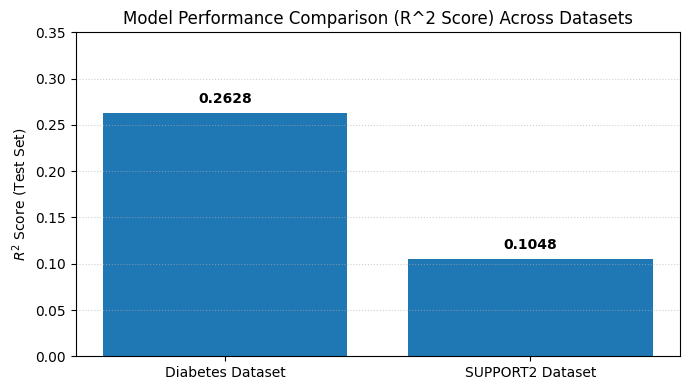

In [19]:
#R2 scores fromresults
datasets = ['Diabetes Dataset', 'SUPPORT2 Dataset']
r2_scores = [0.2628, 0.1048]

plt.figure(figsize=(7, 4))
bars = plt.bar(datasets, r2_scores,)
plt.title('Model Performance Comparison (R^2 Score) Across Datasets')
plt.ylabel('$R^2$ Score (Test Set)')
plt.ylim(0, 0.35)

#numerical text labels on top of the bars
for bar in bars:
  yval = bar.get_height()
  plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.008, f'{yval:.4f}', ha='center', va='bottom', fontweight='bold')

plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()